In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utilidades import Mascara, VegetacionMedia, Serie, Ajuste, Autocorrelacion

In [2]:
archivo = 'campo_aguerre_sm.npz'
with np.load(archivo, allow_pickle=False) as z:
    print('Variables:', z.files)
    cubo = z['cubo']
    t = z['tiempo_interpolado']
    mascara = z['dentrofuera']

print('EVI:', cubo.shape, 
      '| tiempo:', t.shape, '| máscara:', mascara.shape)
assert cubo.shape[:2] == mascara.shape
assert np.all(np.diff(t) > 0), 'El tiempo debe ser estrictamente creciente.'

Variables: ['tiempo', 'cubo', 'DAY', 'nt', 'dentrofuera', 'calidad', 'tiempo_interpolado', 'cuboclima']
EVI: (170, 65, 604) | tiempo: (604,) | máscara: (170, 65)


In [3]:
evi = np.asarray(cubo, dtype=float).transpose(1, 0, 2)[::-1, :, :].copy()
mascara_transposed = mascara.transpose()[::-1,:]

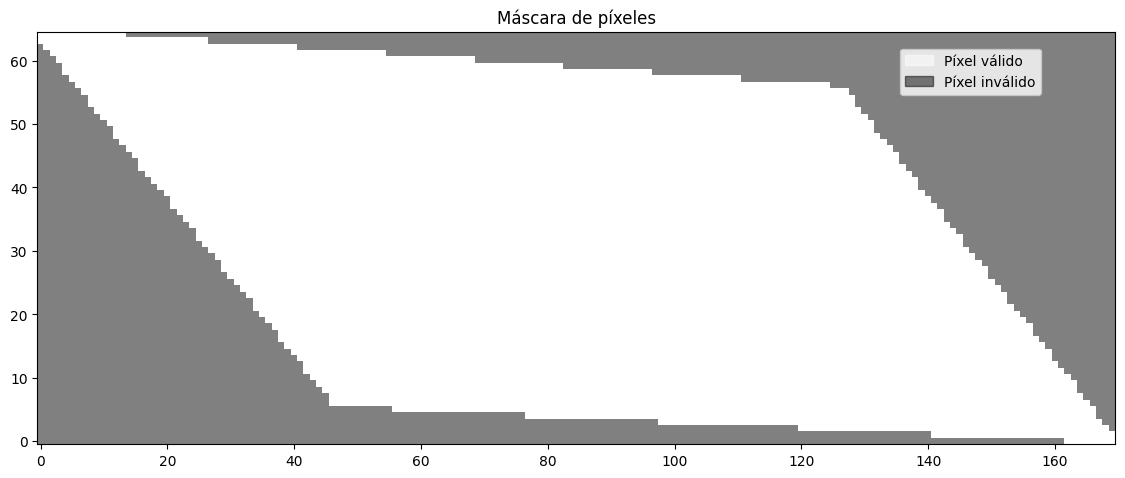

In [4]:
m = Mascara(mascara_transposed, valor_valido=False, valor_invalido=True)
m.dibujo(ancho=14)

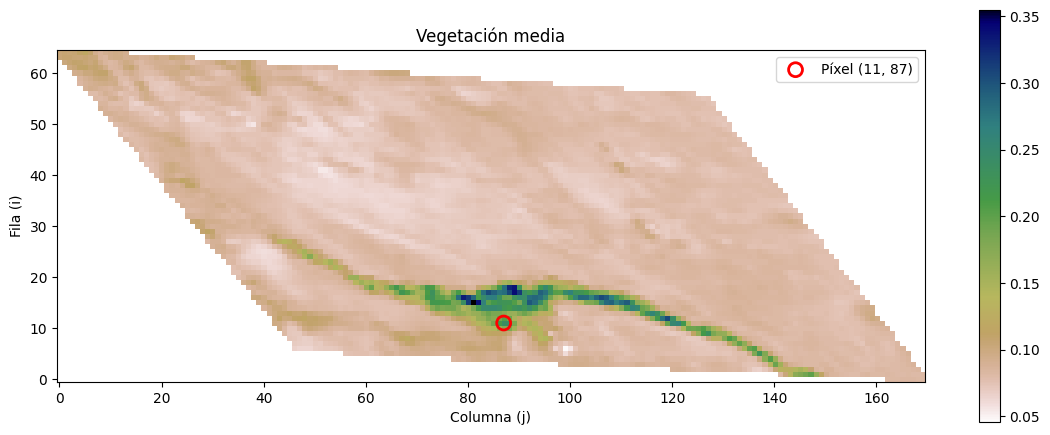

In [25]:
mapa = VegetacionMedia(m.enmascara(evi))
mapa.dibujo(ancho=14, i =11, j=87)

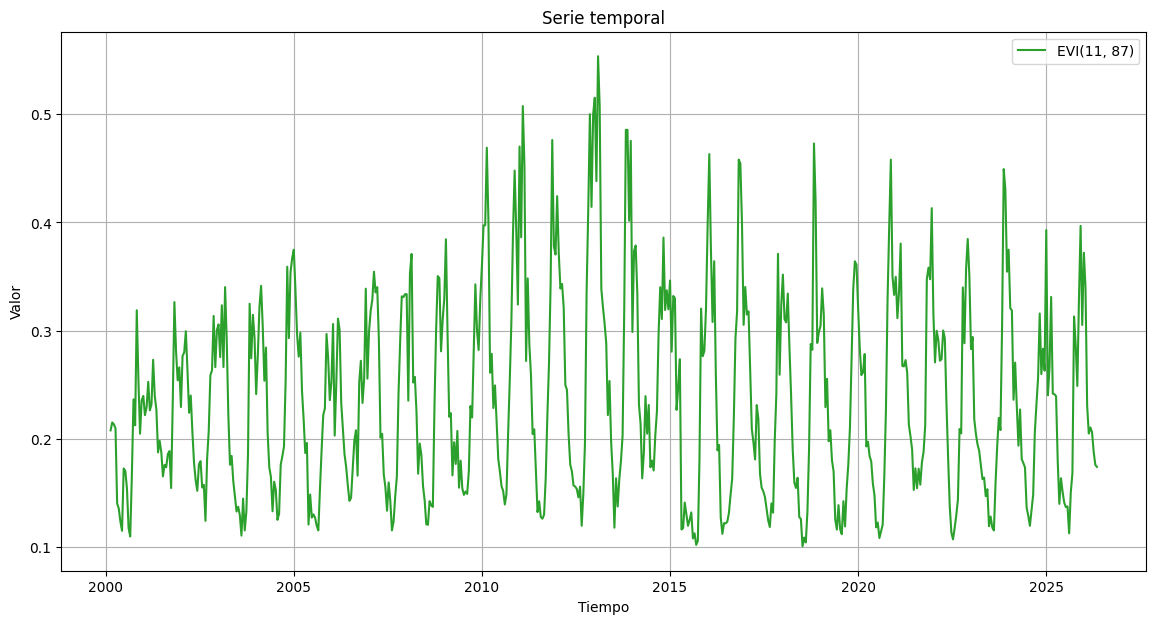

In [26]:
s = Serie(evi[11,87,:], t, "EVI(11, 87)")
s.dibujo(ancho=14)

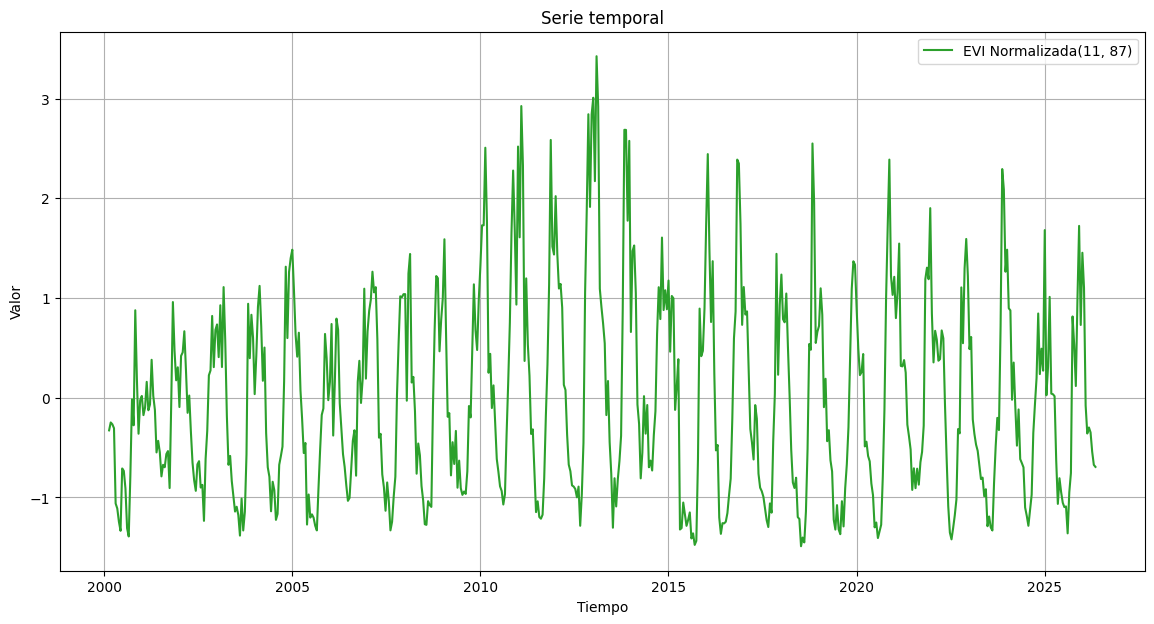

In [11]:
valores = evi[11,87,:]
s = Serie((valores-valores.mean())/valores.std(), t, "EVI Normalizada(11, 87)")
s.dibujo(ancho=14)

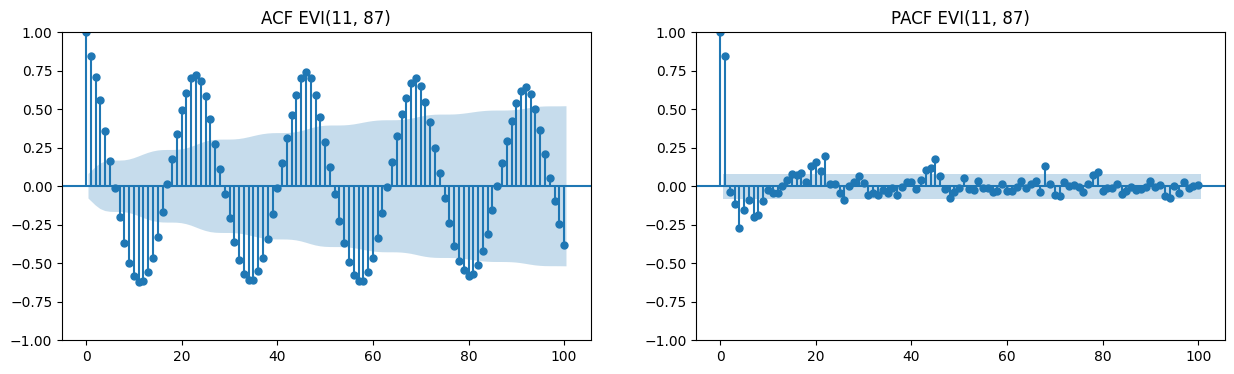

In [12]:
autocorrelacion = Autocorrelacion(t, valores, "EVI(11, 87)")
autocorrelacion.grafico()

In [13]:
acf = np.array(autocorrelacion.acf())
peaks = np.where((acf[1:-1] > acf[:-2]) & (acf[1:-1] > acf[2:]))[0] + 1
peaks

array([23, 46, 69, 92])

In [14]:
autocorrelacion.pacf_significativos()

[(1, np.float64(0.847)),
 (3, np.float64(-0.113)),
 (4, np.float64(-0.273)),
 (5, np.float64(-0.151)),
 (6, np.float64(-0.089)),
 (7, np.float64(-0.197)),
 (8, np.float64(-0.19)),
 (9, np.float64(-0.098)),
 (17, np.float64(0.088)),
 (19, np.float64(0.132)),
 (20, np.float64(0.158)),
 (21, np.float64(0.097)),
 (22, np.float64(0.199)),
 (26, np.float64(-0.089)),
 (43, np.float64(0.105)),
 (44, np.float64(0.118)),
 (45, np.float64(0.177)),
 (68, np.float64(0.133)),
 (79, np.float64(0.094))]

In [16]:
b_serie = valores[~np.isnan(valores)]
t_serie = t[~np.isnan(valores)]

ajuste = Ajuste(b_serie, t_serie, 24)
modelos =ajuste.evaluar_modelos()

RBF                   RMSE=0.07528  cobertura=100.0%  logML=-444.24  k=3  AIC=894.49
   0.906**2 * RBF(length_scale=0.135) + WhiteKernel(noise_level=0.117)
Matérn 3/2            RMSE=0.07366  cobertura=100.0%  logML=-439.81  k=3  AIC=885.61
   0.998**2 * Matern(length_scale=0.207, nu=1.5) + WhiteKernel(noise_level=0.0937)
RationalQuadratic     RMSE=0.07441  cobertura=100.0%  logML=-441.27  k=4  AIC=890.55
   0.943**2 * RationalQuadratic(alpha=3.3, length_scale=0.14) + WhiteKernel(noise_level=0.111)


/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__periodicity is close to the specified lower bound 0.5. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified upper bound 0.25. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Periódico Puro        RMSE=0.04715  cobertura=91.7%  logML=-529.38  k=4  AIC=1066.77
   0.789**2 * ExpSineSquared(length_scale=0.05, periodicity=0.5) + WhiteKernel(noise_level=0.25)
Periódico + Matérn    RMSE=0.04976  cobertura=91.7%  logML=-349.33  k=6  AIC=710.65
   0.688**2 * ExpSineSquared(length_scale=0.502, periodicity=1) + 0.468**2 * Matern(length_scale=0.154, nu=1.5) + WhiteKernel(noise_level=0.0946)


RBF (np.float64(0.0752819832258924), np.float64(1.0), np.float64(894.485325805659))
Matérn 3/2 (np.float64(0.07365714602038201), np.float64(1.0), np.float64(885.6117728287211))
RationalQuadratic (np.float64(0.074413391334259), np.float64(1.0), np.float64(890.5456912369646))
Periódico Puro (np.float64(0.04715106554913352), np.float64(0.9166666666666666), np.float64(1066.7681724454328))
Periódico + Matérn (np.float64(0.049756940187886664), np.float64(0.9166666666666666), np.float64(710.6511105632306))


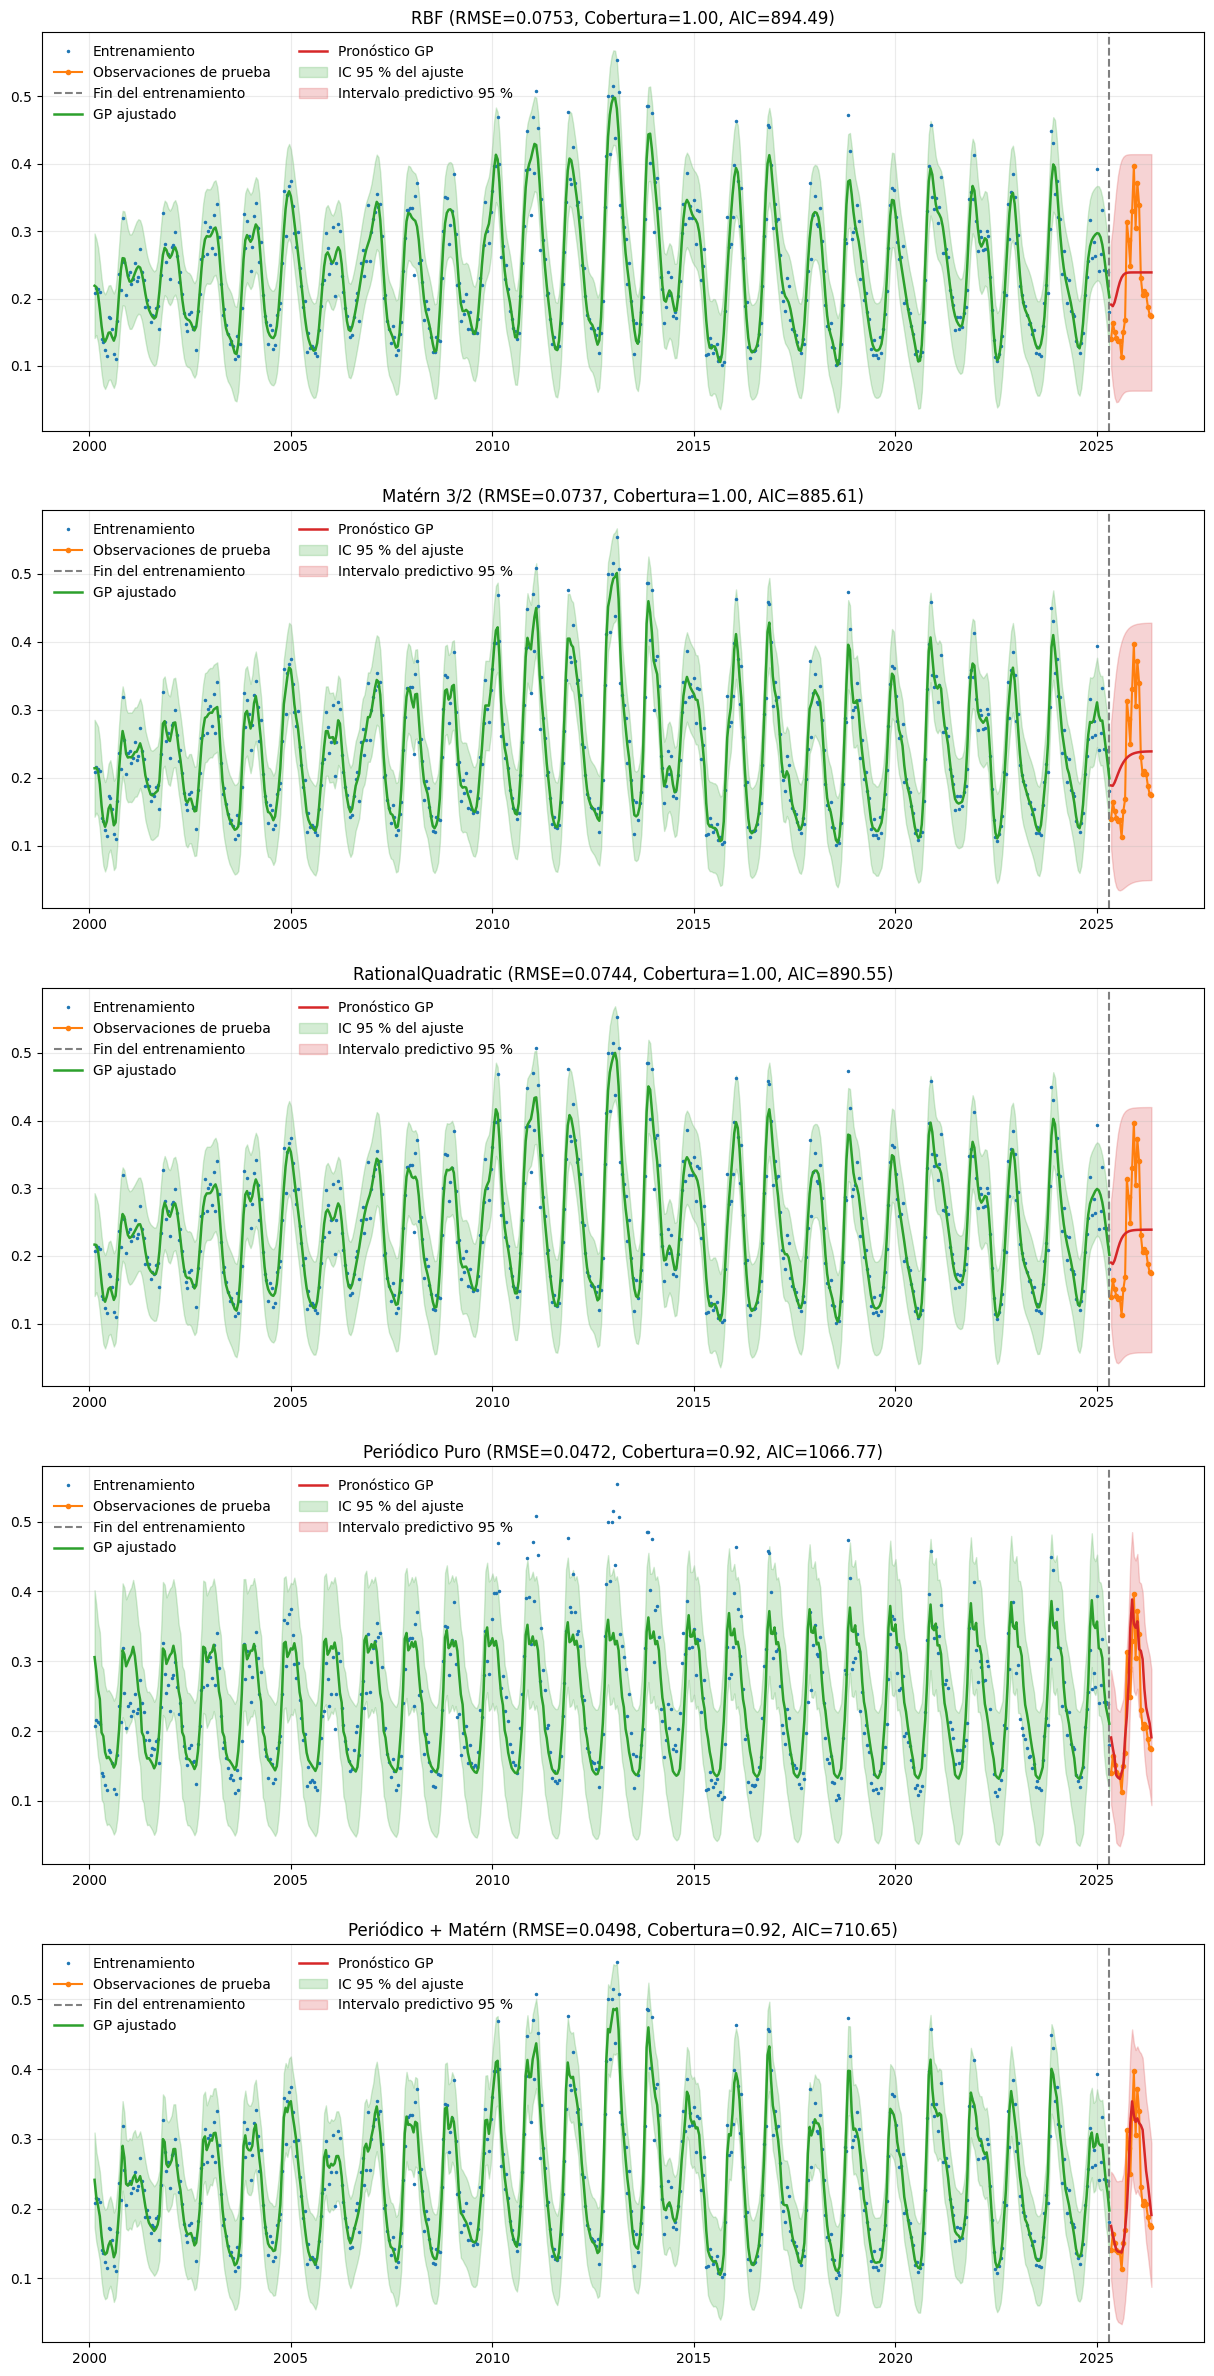

In [17]:
fig, ax = plt.subplots(len(modelos), 1, figsize=(15, 6 * len(modelos)))
for i, nombre in enumerate(modelos):
    print(nombre, modelos[nombre][3:])
    ajuste.dibujo(modelos[nombre][0], ax=ax[i], title=f"{nombre} (RMSE={modelos[nombre][3]:.4f}, Cobertura={modelos[nombre][4]:.2f}, AIC={modelos[nombre][5]:.2f})")

In [18]:
df = ajuste.validacion_kernels()

/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home

In [19]:

df.groupby('kernel')["error^2"].mean().sort_values(ascending=True)

kernel
Periódico Puro        0.001798
Periódico + Matérn    0.001994
RBF                   0.005834
RationalQuadratic     0.006268
Matérn 3/2            0.006787
Name: error^2, dtype: float64

## Residuos
### Kernel Periódico + Matérn
#### Residuos Entrenamiento

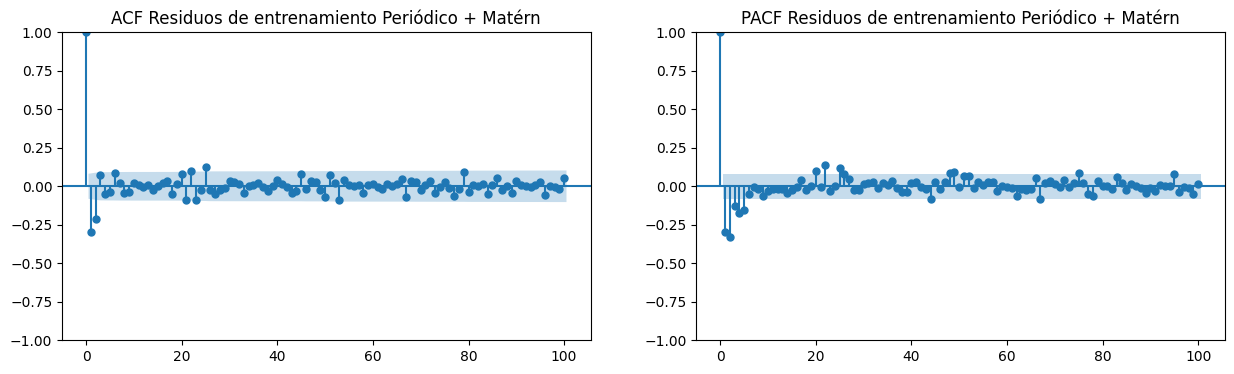

In [45]:
media_entrenamiento, _,media_prueba,_ = ajuste.estimacion(modelos["Periódico + Matérn"][0], ajuste.t_entrenamiento, ajuste.b_entrenamiento, ajuste.t_prueba)
Autocorrelacion(ajuste.t_entrenamiento, ajuste.b_entrenamiento - media_entrenamiento, "Residuos de entrenamiento Periódico + Matérn").grafico()

#### Residuos Prueba

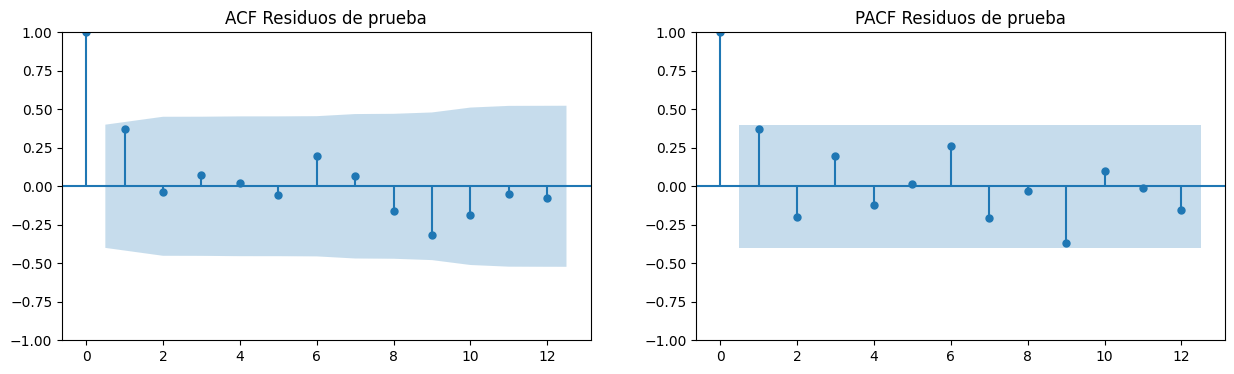

In [ ]:
Autocorrelacion(ajuste.t_prueba, ajuste.b_prueba - media_prueba, "Residuos de prueba Periódico + Matérn").grafico(lags=12)

### Kernel Periódico Puro
#### Residuos Entrenamiento

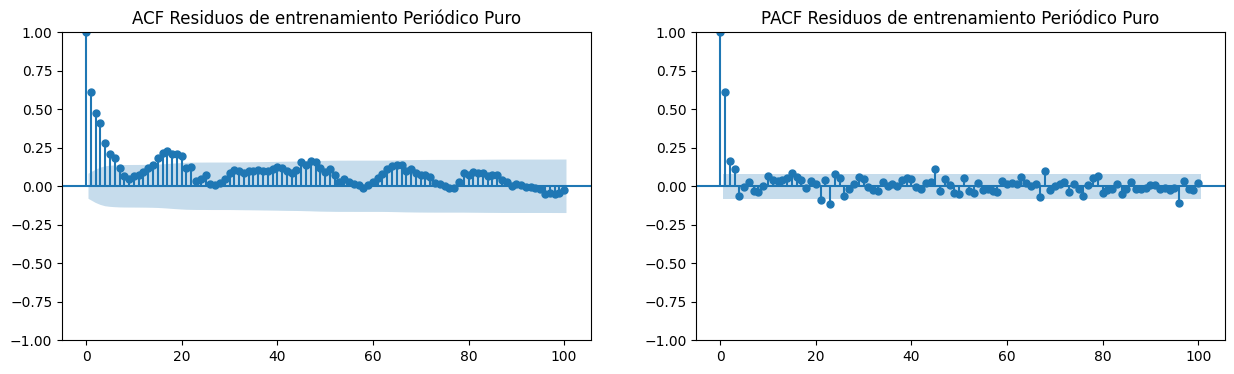

In [47]:
media_entrenamiento, _,media_prueba,_ = ajuste.estimacion(modelos["Periódico Puro"][0], ajuste.t_entrenamiento, ajuste.b_entrenamiento, ajuste.t_prueba)
Autocorrelacion(ajuste.t_entrenamiento, ajuste.b_entrenamiento - media_entrenamiento, "Residuos de entrenamiento Periódico Puro").grafico()

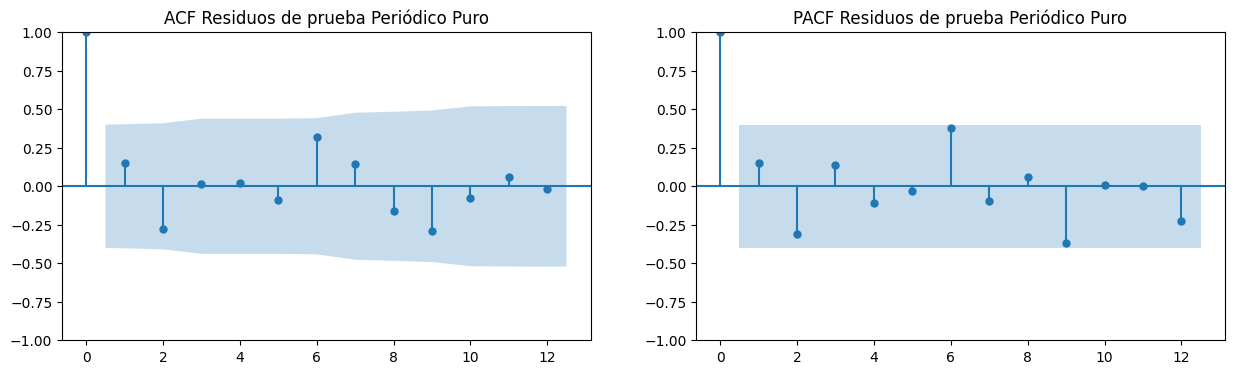

In [48]:
Autocorrelacion(ajuste.t_prueba, ajuste.b_prueba - media_prueba, "Residuos de prueba Periódico Puro").grafico(lags=12)